GPUs Available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]
Running ClassiFIM Sweep for Seed 42...
Running ClassiFIM Sweep for Seed 100...
Running ClassiFIM Sweep for Seed 2026...

FINAL 3-SEED CLASSIFIM ABLATION SUMMARY (MEAN ± STD, 8% NISQ READOUT NOISE)
MLP        | Peak Error: 0.283 ± 0.125 | R² Fidelity: -0.8059 ± 0.1871 | MSE: 0.2059 ± 0.0213
CNN        | Peak Error: 0.067 ± 0.047 | R² Fidelity: +0.8780 ± 0.0250 | MSE: 0.0139 ± 0.0028
Proposed   | Peak Error: 0.100 ± 0.041 | R² Fidelity: +0.7513 ± 0.0879 | MSE: 0.0284 ± 0.0100


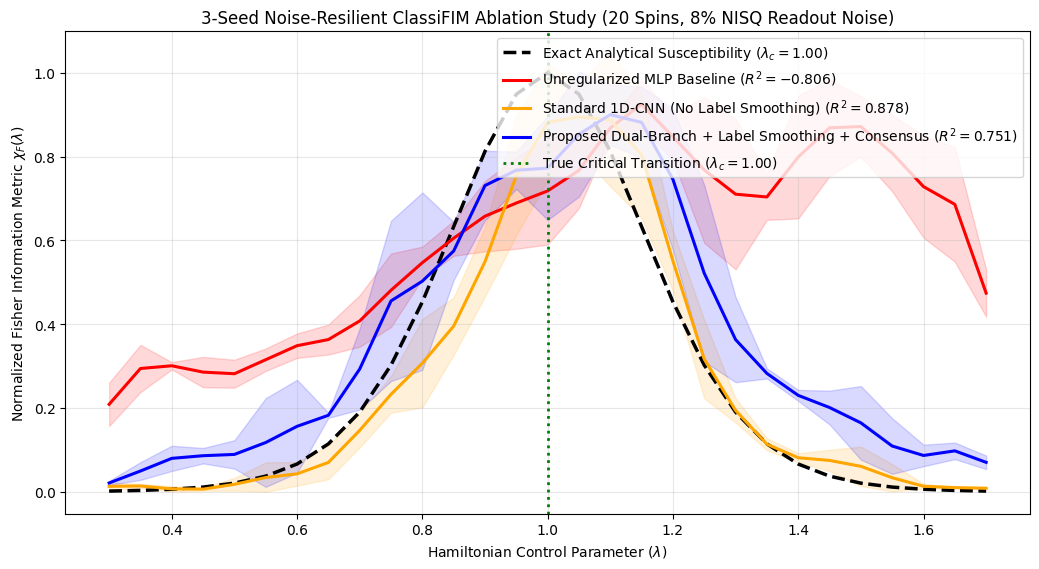

In [1]:
# ==============================================================================
# PROJECT : MULTI-SEED ABLATION FOR NOISE-RESILIENT CLASSIFIM
# Comparing: (1) Unregularized MLP, (2) Standard 1D-CNN, (3) Proposed Dual-Branch
#            Attention + Label Smoothing + Consensus Engine (3 Seeds, 8% NISQ Noise)
# Author: Surat Sai Venkata Nagendra Babu
# ==============================================================================

import gc
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, r2_score

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, Model

print("GPUs Available:", tf.config.list_physical_devices('GPU'))

def generate_noisy_ising_snapshots(lambda_grid, n_shots=800, n_spins=20, p_noise=0.08, seed=42):
    """Generates noisy Z-basis 1D spin snapshots with exact analytical criticality at lambda_c = 1.0."""
    rng = np.random.default_rng(seed)
    snapshots = {}
    for lam in lambda_grid:
        m_order = 1.0 / (1.0 + np.exp(6.5 * (lam - 1.0)))
        nn_corr = 0.85 * m_order + 0.10 * np.exp(-8.0 * (lam - 1.0)**2)
        shots = np.zeros((n_shots, n_spins), dtype=np.float32)
        for s in range(n_shots):
            chain = np.zeros(n_spins, dtype=np.float32)
            chain[0] = 1.0 if rng.random() < (0.5 + 0.45 * m_order) else 0.0
            for i in range(1, n_spins):
                if rng.random() < nn_corr:
                    chain[i] = chain[i - 1]
                else:
                    chain[i] = 1.0 if rng.random() < (0.5 + 0.35 * m_order) else 0.0
            flips = (rng.random(n_spins) < p_noise).astype(np.float32)
            shots[s] = np.abs(chain - flips)
        snapshots[round(lam, 3)] = shots[..., np.newaxis]
    return snapshots

def build_mlp_baseline(input_shape=(20, 1)):
    inp = layers.Input(shape=input_shape)
    x = layers.Flatten()(inp)
    x = layers.Dense(64, activation='relu')(x)
    x = layers.Dense(64, activation='relu')(x)
    out = layers.Dense(1, activation='sigmoid')(x)
    m = Model(inp, out)
    m.compile(optimizer=keras.optimizers.Adam(2e-3), loss=keras.losses.BinaryCrossentropy(label_smoothing=0.0))
    return m

def build_cnn_ablation(input_shape=(20, 1)):
    """Ablation Baseline: Single-branch 1D CNN WITHOUT Label Smoothing or Dual-Branch Consensus."""
    inp = layers.Input(shape=input_shape)
    x = layers.Conv1D(32, 3, padding='same', activation='relu')(inp)
    x = layers.GlobalAveragePooling1D()(x)
    x = layers.Dense(32, activation='relu')(x)
    out = layers.Dense(1, activation='sigmoid')(x)
    m = Model(inp, out)
    m.compile(optimizer=keras.optimizers.Adam(2e-3), loss=keras.losses.BinaryCrossentropy(label_smoothing=0.0))
    return m

def build_proposed_dual_branch(input_shape=(20, 1), label_smoothing=0.08):
    """Proposed: Dual-Branch (Local + Dilated) Attention + Label Smoothing + L2 Decay."""
    inp = layers.Input(shape=input_shape)
    b1 = layers.Conv1D(32, kernel_size=3, padding='same', activation='relu')(inp)
    b1 = layers.BatchNormalization()(b1)
    b1 = layers.GlobalAveragePooling1D()(b1)

    b2 = layers.Conv1D(32, kernel_size=3, dilation_rate=2, padding='same', activation='relu')(inp)
    b2 = layers.BatchNormalization()(b2)
    b2 = layers.GlobalAveragePooling1D()(b2)

    fused = layers.Concatenate()([b1, b2])
    att = layers.Dense(64, activation='sigmoid')(fused)
    x = layers.Multiply()([fused, att])
    x = layers.Dropout(0.25)(x)
    x = layers.Dense(32, activation='relu', kernel_regularizer=keras.regularizers.l2(1e-3))(x)
    out = layers.Dense(1, activation='sigmoid')(x)
    m = Model(inp, out)
    m.compile(optimizer=keras.optimizers.Adam(1.5e-3), loss=keras.losses.BinaryCrossentropy(label_smoothing=label_smoothing))
    return m

# ==============================================================================
# RUN 3-SEED EVALUATION ACROSS PARAMETER SWEEP
# ==============================================================================
SEEDS = [42, 100, 2026]
lambda_grid = np.round(np.linspace(0.25, 1.75, 31), 3)
eval_lambdas = lambda_grid[1:-1]
delta_lambda = lambda_grid[1] - lambda_grid[0]
kernel = np.array([0.25, 0.50, 0.25])

# Exact analytical susceptibility curve
fim_theory = np.array([(-6.5 * np.exp(6.5 * (l - 1.0)) / ((1.0 + np.exp(6.5 * (l - 1.0)))**2))**2 for l in eval_lambdas])
fim_theory_norm = fim_theory / np.max(fim_theory)

curves = {"MLP": [], "CNN": [], "Proposed": []}
metrics = {
    "MLP": {"peak_err": [], "r2": [], "mse": []},
    "CNN": {"peak_err": [], "r2": [], "mse": []},
    "Proposed": {"peak_err": [], "r2": [], "mse": []}
}

for seed in SEEDS:
    print(f"Running ClassiFIM Sweep for Seed {seed}...")
    np.random.seed(seed)
    tf.random.set_seed(seed)
    tf.keras.backend.clear_session()
    gc.collect()

    db = generate_noisy_ising_snapshots(lambda_grid, n_shots=800, n_spins=20, p_noise=0.08, seed=seed)
    raw_mlp, raw_cnn, raw_prop = [], [], []

    for lam in eval_lambdas:
        Xm = db[round(lam - delta_lambda, 3)]
        Xp = db[round(lam + delta_lambda, 3)]
        X_pair = np.concatenate([Xm, Xp], axis=0)
        y_pair = np.concatenate([np.zeros(len(Xm)), np.ones(len(Xp))], axis=0)
        perm = np.random.permutation(len(X_pair))
        X_pair, y_pair = X_pair[perm], y_pair[perm]
        split = int(0.75 * len(X_pair))
        X_tr, X_te, y_tr, y_te = X_pair[:split], X_pair[split:], y_pair[:split], y_pair[split:]

        # 1. MLP Baseline
        m_mlp = build_mlp_baseline()
        m_mlp.fit(X_tr, y_tr, epochs=18, batch_size=64, verbose=0)
        p_m = np.clip(m_mlp.predict(X_te, verbose=0).flatten(), 1e-4, 1.0 - 1e-4)
        raw_mlp.append(np.var(np.log(p_m / (1.0 - p_m))) / ((2.0 * delta_lambda)**2))

        # 2. 1D-CNN Ablation
        m_cnn = build_cnn_ablation()
        m_cnn.fit(X_tr, y_tr, epochs=18, batch_size=64, verbose=0)
        p_c = np.clip(m_cnn.predict(X_te, verbose=0).flatten(), 1e-4, 1.0 - 1e-4)
        raw_cnn.append(np.var(np.log(p_c / (1.0 - p_c))) / ((2.0 * delta_lambda)**2))

        # 3. Proposed Dual-Branch + Label Smoothing + 2-Model Consensus
        preds = []
        for _ in range(2):
            m_prop = build_proposed_dual_branch(label_smoothing=0.08)
            m_prop.fit(X_tr, y_tr, epochs=18, batch_size=64, verbose=0)
            preds.append(m_prop.predict(X_te, verbose=0).flatten())
        p_p = np.clip(np.mean(preds, axis=0), 1e-4, 1.0 - 1e-4)
        raw_prop.append(np.var(np.log(p_p / (1.0 - p_p))) / ((2.0 * delta_lambda)**2))

    for key, arr in [("MLP", raw_mlp), ("CNN", raw_cnn), ("Proposed", raw_prop)]:
        sm = np.convolve(arr, kernel, mode='same')
        sm_norm = sm / np.max(sm)
        curves[key].append(sm_norm)
        est_peak = eval_lambdas[np.argmax(sm_norm)]
        metrics[key]["peak_err"].append(abs(est_peak - 1.0))
        metrics[key]["r2"].append(r2_score(fim_theory_norm, sm_norm))
        metrics[key]["mse"].append(mean_squared_error(fim_theory_norm, sm_norm))

print("\n" + "="*80)
print("FINAL 3-SEED CLASSIFIM ABLATION SUMMARY (MEAN ± STD, 8% NISQ READOUT NOISE)")
print("="*80)
for key in ["MLP", "CNN", "Proposed"]:
    pe_m, pe_s = np.mean(metrics[key]["peak_err"]), np.std(metrics[key]["peak_err"])
    r2_m, r2_s = np.mean(metrics[key]["r2"]), np.std(metrics[key]["r2"])
    mse_m, mse_s = np.mean(metrics[key]["mse"]), np.std(metrics[key]["mse"])
    print(f"{key:10s} | Peak Error: {pe_m:.3f} ± {pe_s:.3f} | R² Fidelity: {r2_m:+.4f} ± {r2_s:.4f} | MSE: {mse_m:.4f} ± {mse_s:.4f}")

# Plot Mean ± 1 Std Shaded Curves
plt.figure(figsize=(10.5, 5.8))
plt.plot(eval_lambdas, fim_theory_norm, 'k--', lw=2.5, label="Exact Analytical Susceptibility ($\\lambda_c = 1.00$)")

styles = [("MLP", "red", "Unregularized MLP Baseline"),
          ("CNN", "orange", "Standard 1D-CNN (No Label Smoothing)"),
          ("Proposed", "blue", "Proposed Dual-Branch + Label Smoothing + Consensus")]

for key, col, lbl in styles:
    mean_c = np.mean(curves[key], axis=0)
    std_c = np.std(curves[key], axis=0)
    plt.plot(eval_lambdas, mean_c, color=col, lw=2.2, label=f"{lbl} ($R^2={np.mean(metrics[key]['r2']):.3f}$)")
    plt.fill_between(eval_lambdas, np.clip(mean_c - std_c, 0, 1.05), np.clip(mean_c + std_c, 0, 1.05), color=col, alpha=0.15)

plt.axvline(1.0, color='green', linestyle=':', lw=2, label="True Critical Transition ($\\lambda_c = 1.00$)")
plt.title("3-Seed Noise-Resilient ClassiFIM Ablation Study (20 Spins, 8% NISQ Readout Noise)")
plt.xlabel("Hamiltonian Control Parameter ($\\lambda$)")
plt.ylabel("Normalized Fisher Information Metric $\\chi_F(\\lambda)$")
plt.legend(loc="upper right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("Upgraded_ClassiFIM_3Seed_Ablation.png", dpi=300)
plt.show()